# 02 · Tres estados del diagnóstico

Los controles de curva aíslan el diagnóstico del muestreo geométrico: una ley lineal, una curva y un intervalo con pocas observaciones. La traza sintética del cuaderno 01 aporta además un diagnóstico geométrico completo.

In [1]:
from pathlib import Path
import os
import sys
import time
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from shapely.geometry import LineString, box
from pyproj import CRS

started_wall, started_cpu = time.perf_counter(), time.process_time()
repository = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/musa").is_dir())
sys.path.insert(0, str(repository / "src"))
sys.path.insert(0, str(repository / "scripts"))
from musa import MUSA, ScalingOptions, assess_lineament_scaling, write_scaling_reports
crs = CRS.from_proj4("+proj=eqc +R=6371000 +units=m +no_defs +type=crs")
lines = [LineString([(1000, 1500), (9000, 6500)])]
domain = box(0, 0, 10000, 10000)
scales = np.geomspace(10, 1000, 16)
model = MUSA.from_line_geometries(lines, domain, crs, q_values=[0, 1, 2])
output = Path(os.environ.get("MUSA_NOTEBOOK_OUTPUT_ROOT", repository / "outputs/notebooks")) / "02_scaling_states"
output.mkdir(parents=True, exist_ok=True)
def save_figure(figure, name):
    target = output / (name + ".png")
    figure.savefig(target, dpi=120, bbox_inches="tight")
    display(Image(filename=str(target)))
    plt.close(figure)
print("Synthetic inputs; unlocated model metres. Outputs:", output.name)


Synthetic inputs; unlocated model metres. Outputs: 02_scaling_states


## Controles declarados

La opción exige ocho escalas y una década. La curva se construye antes de evaluar los estados.

,control,status,dimension,reasons
0,lineal,compatible_finite_range,1.200000,[]
1,curva,not_supported,-0.181551,"[poor_linear_fit, dimension_outside_planar_ran..."
2,cuatro escalas,insufficient_information,NaN,"[too_few_resolved_scales, short_scaling_interval]"


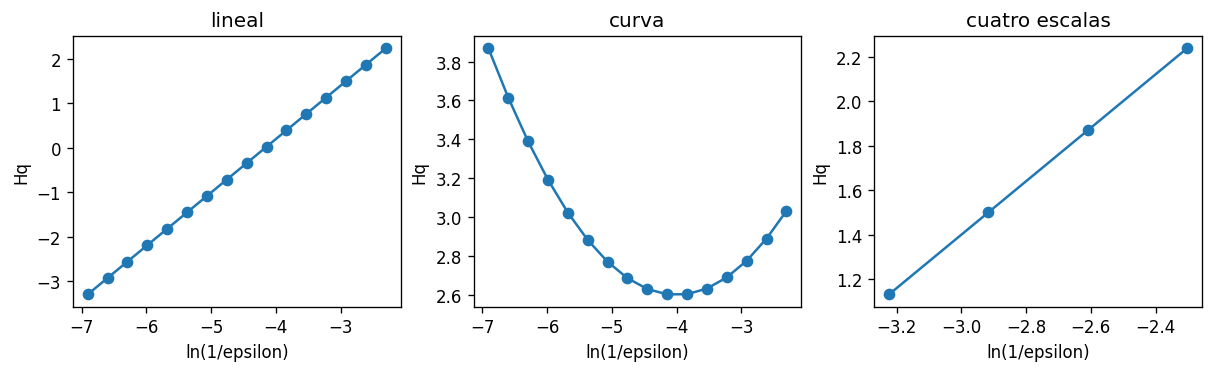

In [2]:
from musa.scaling import assess_curve
x = np.log(1/scales)
options = ScalingOptions(1)
controls = {"lineal": (scales, 5+1.2*x),
            "curva": (scales, 5+1.2*x+.15*x*x),
            "cuatro escalas": (scales[:4], (5+1.2*x)[:4])}
reports = {name: assess_curve(s, h, options) for name, (s, h) in controls.items()}
assert {r["status"] for r in reports.values()} == {"compatible_finite_range", "not_supported", "insufficient_information"}
table = pd.DataFrame([dict(control=k, status=r["status"], dimension=r.get("dimension"), reasons=r["reasons"]) for k,r in reports.items()])
display(table)
table.to_csv(output / "three_states.csv", index=False)
(output / "three_states.json").write_text(json.dumps(reports, indent=2), encoding="utf-8")
figure, axes = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
for ax, (name, (s, h)) in zip(axes, controls.items()):
    ax.plot(np.log(1/s), h, "o-")
    ax.set(title=name, xlabel="ln(1/epsilon)", ylabel="Hq")
save_figure(figure, "states")

## Interpretación

Compatible se refiere al intervalo probado. Sin respaldo conserva el motivo del fallo. Información insuficiente conserva la ausencia de una dimensión; nunca se sustituye por cero.

In [3]:
full = assess_lineament_scaling(model, scales, ScalingOptions(1, renyi_order_policy="inform_q0_q2"))
short = assess_lineament_scaling(model, scales[:4], ScalingOptions(1))
assert all(row["dimension"] is None for row in short["q_results"])
write_scaling_reports(output / "maps", [full, dict(short, support_id="short")])
display(pd.DataFrame(full["q_results"])[["q", "status", "dimension"]])

,q,status,dimension
0,0.0,compatible_finite_range,0.986590
1,1.0,compatible_finite_range,0.991085
2,2.0,compatible_finite_range,0.993307


In [4]:
metrics = dict(wall_seconds=time.perf_counter()-started_wall,
               cpu_seconds_kernel=time.process_time()-started_cpu)
(output / "execution.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(json.dumps(metrics))


{"wall_seconds": 3.2150164000004224, "cpu_seconds_kernel": 3.21875}
